# Bài 07: Học Không Giám sát trên Ảnh — Phân cụm (K-Means, DBSCAN) và Giảm chiều Dữ liệu (PCA)

## 1. Mục tiêu học tập
- Hiểu bài toán **Học không giám sát (`Unsupervised Learning`)** khi không có nhãn lớp $y$:
  1. **Phân cụm (`Clustering`)** bằng `K-Means` (gom cụm đặc trưng ảnh & ứng dụng nén số lượng màu sắc trong ảnh – *Color Quantization*) và `DBSCAN` (phân cụm dựa trên mật độ và phát hiện mẫu ngoại lai).
  2. **Giảm chiều dữ liệu (`Dimensionality Reduction`)** bằng `PCA (Principal Component Analysis)`.
- **Làm rõ nhận thức quan trọng**: `PCA` là thuật toán tìm hệ trục tọa độ trực giao mới giữ lại nhiều phương sai nhất để nén số chiều hoặc trực quan hóa `2D/3D`, **PCA KHÔNG PHẢI là mô hình phân loại**!

## 2. Kiến thức cần có
- Đã hoàn thành Bài 05 và Bài 06.

## 3. Thời gian học dự kiến
- Khoảng **2.0 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
1. Bạn nhận được một kho gồm hàng nghìn bức ảnh chưa kịp gán nhãn và muốn gom các ảnh có hình dạng tương tự nhau thành các nhóm để gán nhãn nhanh hơn (`Clustering`), đồng thời lọc ra những bức ảnh bị hỏng/dị thường (`DBSCAN outliers`).
2. Vector ảnh trải phẳng có hàng nghìn chiều gây chậm cho `k-NN` / `SVM`; bạn cần dùng `PCA` nén xuống `20` chiều mà vẫn giữ được `>90%` lượng thông tin.

## 5. Giải thích trực quan & Công thức Toán học
1. **K-Means Clustering**: Tối ưu hóa tổng bình phương khoảng cách từ mỗi điểm $x_i$ tới tâm cụm $\mu_k$ gần nhất (**Inertia / Within-Cluster Sum of Squares**):
   $$J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|_2^2$$
2. **DBSCAN (`Density-Based Spatial Clustering of Applications with Noise`)**:
   - Quét bán kính $\epsilon$ (`eps`) quanh mỗi điểm. Nếu có ít nhất `min_samples` điểm trong bán kính đó, điểm đó là **Core Point (Điểm lõi)** và mở rộng cụm liên thông.
   - Những điểm đứng cô lập ở vùng thưa sẽ được gán nhãn **`-1` (Noise / Outlier)**!
3. **PCA (Phân tích Thành phần Chính)**:
   - Dịch dữ liệu về tâm $0$, phân rã trị riêng của ma trận hiệp phương sai $\Sigma = \frac{1}{N} X^T X = V \Lambda V^T$.
   - Chọn $K$ vector riêng ứng với $K$ trị riêng lớn nhất ($\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_K$) làm các trục thành phần chính (**Principal Components** / **Eigen-images**).
   - **Tỷ lệ phương sai giữ lại (`Explained Variance Ratio`)**: $\frac{\sum_{j=1}^K \lambda_j}{\sum_{j=1}^D \lambda_j}$.

## 6. Thuật ngữ mới & Giải thích Keyword
| Keyword | Nghĩa tiếng Việt | Nhóm | Kiểu / Giá trị | Vai trò & Ảnh hưởng khi Tăng/Giảm |
|---|---|---|---|---|
| `n_clusters` ($K$) | Số cụm cần chia trong K-Means | Phân cụm | `int >= 2` | Phải chọn trước. Tăng $K$ làm `inertia_` luôn giảm; dùng biểu đồ khuỷu tay (`Elbow`) hoặc `Silhouette Score` để chọn $K$ hợp lý. |
| `eps` & `min_samples` | Bán kính lân cận & Số điểm tối thiểu của DBSCAN | Phân cụm | `float > 0`, `int >= 2` | Tăng `eps` làm các cụm dễ dính chùm vào nhau; giảm `eps` quá nhỏ khiến hầu hết dữ liệu bị coi là nhiễu (`label = -1`). |
| `n_components` | Số chiều giữ lại của PCA | Giảm chiều | `int` (số chiều) hoặc `float ∈ (0, 1)` (tỷ lệ phương sai) | Nếu truyền số nguyên `16` → giữ đúng 16 trục đầu; nếu truyền số thực `0.95` → tự động chọn đủ số trục để giữ `95%` phương sai. |
| `explained_variance_ratio_` | Tỷ lệ phương sai giải thích được | Giảm chiều | Mảng `float` tổng $\le 1.0$ | Cho biết mỗi trục PCA chứa bao nhiêu phần trăm thông tin biến thiên của dữ liệu gốc. |


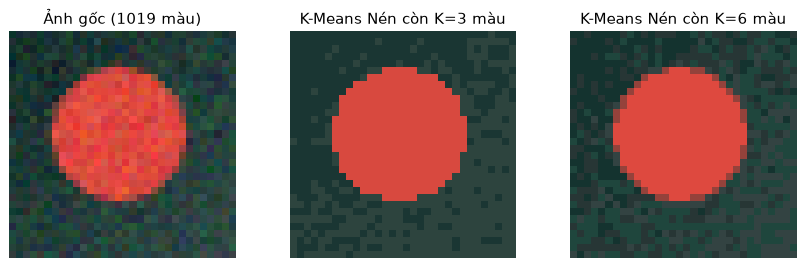

In [1]:
# Cell 1: Ứng dụng K-Means để Nén Màu Ảnh (Color Quantization) và Phân cụm Đặc trưng HOG
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.datasets import load_digits

from src.utils import set_seed
from src.synthetic_data import generate_synthetic_shapes_dataset

set_seed(42)

ds = generate_synthetic_shapes_dataset(num_samples=160, image_size=32, seed=42)
sample_rgb = ds["images"][0]
pixels_2d = sample_rgb.reshape(-1, 3).astype(np.float32)

# Lượng tử hóa màu bức ảnh từ hàng nghìn màu xuống chỉ còn K=3 và K=6 màu đại diện
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.0))
axes[0].imshow(sample_rgb)
axes[0].set_title(f"Ảnh gốc ({len(np.unique(pixels_2d, axis=0))} màu)")
axes[0].axis("off")

for ax, k_colors in zip(axes[1:], [3, 6]):
    km_color = KMeans(n_clusters=k_colors, n_init=5, random_state=42).fit(pixels_2d)
    quantized_pixels = km_color.cluster_centers_[km_color.labels_].reshape(sample_rgb.shape)
    ax.imshow(np.clip(quantized_pixels, 0, 255).astype(np.uint8))
    ax.set_title(f"K-Means Nén còn K={k_colors} màu")
    ax.axis("off")
plt.tight_layout()
plt.show()


Chiều gốc: 64 chiều -> Chỉ cần 21 trục PCA đầu tiên để giữ được >= 90% phương sai (90.3%)!


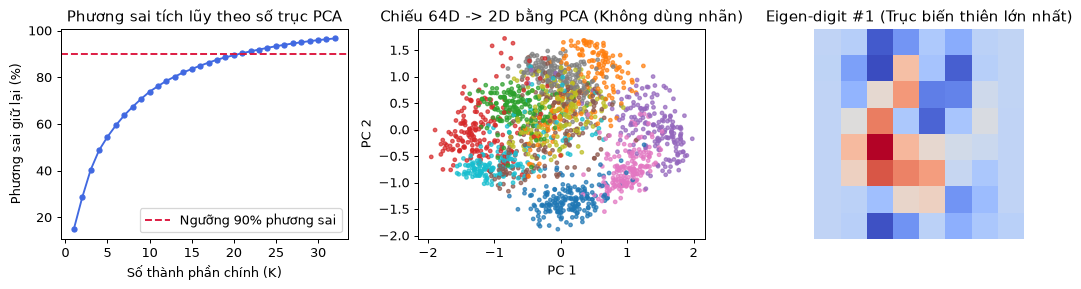

In [2]:
# Cell 2: Thực hành PCA trên bộ dữ liệu chữ số viết tay (load_digits 8x8 = 64 chiều)
# Nguồn dữ liệu: UCI Optical Recognition of Handwritten Digits tích hợp sẵn offline trong scikit-learn
digits = load_digits()
X_digits = digits.data.astype(np.float32) / 16.0  # (1797, 64) trong đoạn [0, 1]
y_digits = digits.target                          # Nhãn 0..9 (chỉ dùng để tô màu hình vẽ kiểm tra, PCA KHÔNG dùng nhãn!)

pca_full = PCA(n_components=32, random_state=42).fit(X_digits)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n_90 = int(np.searchsorted(cum_var, 0.90) + 1)
print(f"Chiều gốc: {X_digits.shape[1]} chiều -> Chỉ cần {n_90} trục PCA đầu tiên để giữ được >= 90% phương sai ({cum_var[n_90-1]*100:.1f}%)!")

# Chiếu dữ liệu 64 chiều xuống mặt phẳng 2D bằng 2 trục PCA đầu tiên và hiển thị Eigen-digits
X_pca_2d = pca_full.transform(X_digits)[:, :2]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].plot(np.arange(1, 33), cum_var * 100, "o-", color="royalblue", markersize=4)
axes[0].axhline(90, color="crimson", linestyle="--", label="Ngưỡng 90% phương sai")
axes[0].set_title("Phương sai tích lũy theo số trục PCA")
axes[0].set_xlabel("Số thành phần chính (K)")
axes[0].set_ylabel("Phương sai giữ lại (%)")
axes[0].legend()

scatter = axes[1].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y_digits, cmap="tab10", s=8, alpha=0.7)
axes[1].set_title("Chiếu 64D -> 2D bằng PCA (Không dùng nhãn)")
axes[1].set_xlabel("PC 1")
axes[1].set_ylabel("PC 2")

# Hiển thị thành phần chính thứ nhất (Eigen-digit #1)
eigen_digit_1 = pca_full.components_[0].reshape(8, 8)
axes[2].imshow(eigen_digit_1, cmap="coolwarm")
axes[2].set_title("Eigen-digit #1 (Trục biến thiên lớn nhất)")
axes[2].axis("off")
plt.tight_layout()
plt.show()


In [3]:
# Cell 3: So sánh K-Means và DBSCAN trong không gian đặc trưng giảm chiều PCA
X_sub = X_pca_2d[:400]
km_feat = KMeans(n_clusters=6, n_init=10, random_state=42).fit(X_sub)
sil_km = silhouette_score(X_sub, km_feat.labels_)

dbscan = DBSCAN(eps=0.32, min_samples=6).fit(X_sub)
n_clusters_db = len(set(dbscan.labels_) - {-1})
n_outliers_db = int((dbscan.labels_ == -1).sum())

print(f"K-Means (K=6) -> Silhouette Score: {sil_km:.3f}")
print(f"DBSCAN        -> Tự tìm thấy {n_clusters_db} cụm đặc và tách riêng {n_outliers_db} điểm ngoại lai (label = -1)")


K-Means (K=6) -> Silhouette Score: 0.395
DBSCAN        -> Tự tìm thấy 2 cụm đặc và tách riêng 1 điểm ngoại lai (label = -1)


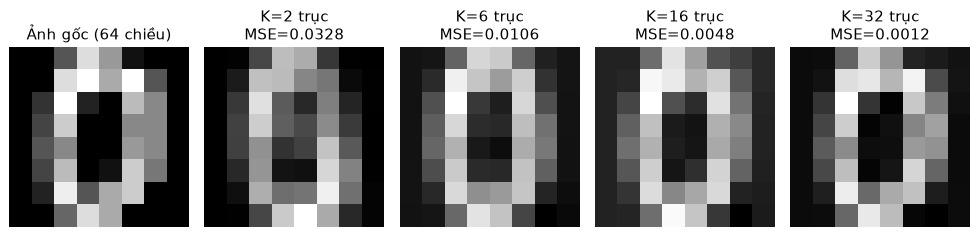

In [4]:
# Cell 4: Thí nghiệm thay đổi một yếu tố — Tái tạo ảnh từ K thành phần chính PCA (K = 2, 8, 24, 64)
sample_digit = X_digits[0:1]  # Chữ số 0
fig, axes = plt.subplots(1, 5, figsize=(11, 2.5))
axes[0].imshow(sample_digit.reshape(8, 8), cmap="gray")
axes[0].set_title("Ảnh gốc (64 chiều)")
axes[0].axis("off")

for ax, k_comp in zip(axes[1:], [2, 6, 16, 32]):
    pca_k = PCA(n_components=k_comp, random_state=42).fit(X_digits)
    code_k = pca_k.transform(sample_digit)
    recon_k = pca_k.inverse_transform(code_k)
    mse_k = float(np.mean((sample_digit - recon_k) ** 2))
    ax.imshow(recon_k.reshape(8, 8), cmap="gray")
    ax.set_title(f"K={k_comp} trục\nMSE={mse_k:.4f}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 2 & 4**: Dù ảnh chữ số có `64` pixel nhưng do các pixel lân cận có tương quan rất cao, chỉ cần `16..21` trục `PCA` đầu tiên đã tái tạo lại chữ số rất rõ nét với sai số `MSE` cực nhỏ.
- **Lưu ý quan trọng**: `PCA` chỉ thực hiện phép quay và chiếu tuyến tính (`transform` / `inverse_transform`). Muốn phân loại chữ số sau khi giảm chiều bằng `PCA`, bạn phải nối thêm một mô hình phân loại phía sau (ví dụ `PCA(n_components=20) -> SVC()`).

## 13. Lỗi thường gặp và cách sửa
1. **Không đưa dữ liệu về cùng thang đo trước khi chạy `PCA` hoặc `K-Means`**: Nếu 1 chiều có biên độ `0..1000` còn chiều kia `0..1`, trục `PCA` đầu tiên sẽ chỉ chạy dọc theo chiều có biên độ lớn.
2. **Tưởng nhãn cụm `0, 1, 2` của `K-Means` trùng với nhãn lớp `0, 1, 2` của bài toán**: Nhãn của `K-Means` chỉ là số thứ tự cụm ngẫu nhiên (hoán vị bất kỳ).

## 14. Bài tập tự làm
- **Cơ bản**: Vẽ đường cong `Inertia` và `Silhouette Score` khi quét `K` của `K-Means` từ `2` đến `10` trên `X_sub`.
- **Trung cấp**: Kết hợp pipeline `PCA(n_components=16)` + `LogisticRegression()` trên bộ `load_digits` (nhớ chia `train/test` trước khi `fit` PCA!) và so sánh tốc độ/độ chính xác với khi không dùng PCA.
- **Nâng cao**: Khảo sát tham số `eps` của `DBSCAN` qua `[0.15, 0.30, 0.60]` và đếm tỷ lệ điểm bị đánh dấu ngoại lai (`label == -1`).

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 07
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# 1. Cơ bản: Quét K cho K-Means
sil_scores = {}
for k in [2, 4, 6, 8, 10]:
    km = KMeans(n_clusters=k, n_init=5, random_state=42).fit(X_sub)
    sil_scores[k] = round(float(silhouette_score(X_sub, km.labels_)), 3)
print("[Cơ bản] Silhouette Score theo K:", sil_scores)

# 2. Trung cấp: Pipeline PCA + LogisticRegression (chia tập trước khi fit PCA)
X_d_tr, X_d_te, y_d_tr, y_d_te = train_test_split(X_digits, y_digits, test_size=0.25, random_state=42, stratify=y_digits)
pca_16 = PCA(n_components=16, random_state=42)
X_d_tr_16 = pca_16.fit_transform(X_d_tr)
X_d_te_16 = pca_16.transform(X_d_te)

clf_full = LogisticRegression(max_iter=500).fit(X_d_tr, y_d_tr)
clf_pca16 = LogisticRegression(max_iter=500).fit(X_d_tr_16, y_d_tr)
print(f"[Trung cấp] 64 chiều gốc Acc={clf_full.score(X_d_te, y_d_te)*100:.1f}% vs 16 chiều PCA Acc={clf_pca16.score(X_d_te_16, y_d_te)*100:.1f}%")

# 3. Nâng cao: Khảo sát eps của DBSCAN
for eps_val in [0.15, 0.30, 0.60]:
    db = DBSCAN(eps=eps_val, min_samples=6).fit(X_sub)
    outlier_pct = (db.labels_ == -1).mean() * 100
    print(f"[Nâng cao] DBSCAN eps={eps_val:.2f} -> Tỷ lệ điểm ngoại lai: {outlier_pct:.1f}%")


[Cơ bản] Silhouette Score theo K: {2: 0.441, 4: 0.487, 6: 0.415, 8: 0.404, 10: 0.441}
[Trung cấp] 64 chiều gốc Acc=96.2% vs 16 chiều PCA Acc=94.2%
[Nâng cao] DBSCAN eps=0.15 -> Tỷ lệ điểm ngoại lai: 28.2%
[Nâng cao] DBSCAN eps=0.30 -> Tỷ lệ điểm ngoại lai: 0.5%
[Nâng cao] DBSCAN eps=0.60 -> Tỷ lệ điểm ngoại lai: 0.0%


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã hoàn thành toàn bộ **Giai đoạn B (Machine Learning Nền tảng)**.
- [x] Phân biệt rõ `PCA` (giảm chiều), `K-Means`/`DBSCAN` (phân cụm) với các mô hình phân loại có giám sát.
- [x] Sẵn sàng bước sang **Giai đoạn C — Bài 08: `08_neural_network_from_scratch.ipynb`**.

## 17. Nguồn tham khảo
- Jolliffe, I. T. (2002), *Principal Component Analysis*, Springer.
- Ester, M. et al. (1996), *A Density-Based Algorithm for Discovering Clusters (DBSCAN)*, KDD.
